In [5]:
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

In [6]:
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

X_train, X_test = X_train.reshape(-1,32*32*3), X_test.reshape(-1,32*32*3)

X_train, X_test = X_train / 255.0, X_test / 255.0
y_train, y_test = to_categorical(y_train, 10), to_categorical(y_test, 10)

In [7]:
model = Sequential([
    Input(shape=(32*32*3,)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='sigmoid')
])

In [8]:
model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [ ]:
history = model.fit(X_train, y_train, validation_split=0.2, epochs=10, batch_size=64)

Epoch 1/10
337/625 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.2266 - loss: 2.0935

In [28]:
test_loss, test_accuracy = model.evaluate(X_test,y_test)
print("Test accuracy: ",test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4881 - loss: 1.4757
Test accuracy:  0.48809999227523804


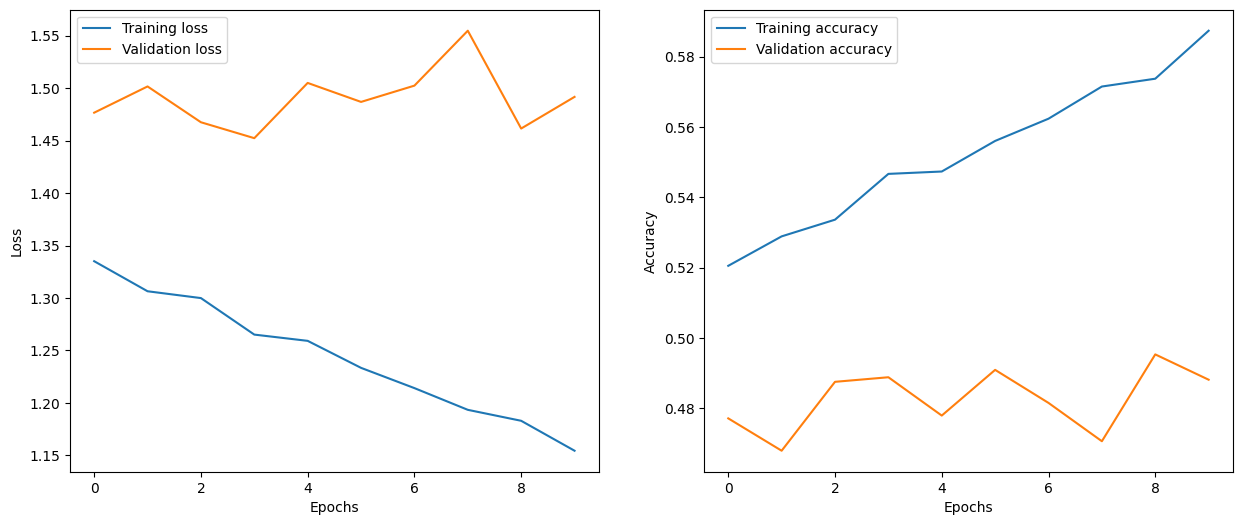

In [30]:
plt.figure(figsize=(15,6))
plt.subplot(1,2,1)
plt.plot(history.history['loss'],label='Training loss')
plt.plot(history.history['val_loss'],label='Validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'],label='Training accuracy')
plt.plot(history.history['val_accuracy'],label='Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()